# 42. Optimization
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

Gradient descent on the quadratic with Hessian $\diag(1,25)$. Left: twenty iterates with the optimal step $\eta=2/(L+\mu)$ (blue) zigzag across the valley, since each gradient points mostly along the steep axis, and are still far from the minimum (star); twenty iterates of the heavy-ball method (red) swing further across the valley at first, but their momentum carries them along the floor, and they reach the minimum. Right: the per-step factor $\abs{1-\eta\lambda}$ applied to an eigencomponent with eigenvalue $\lambda$, for three step sizes, with $[\mu,L]$ shaded; the optimal step equalizes the factor at both ends of the spectrum, and a step above $2/L$ amplifies the steepest component.

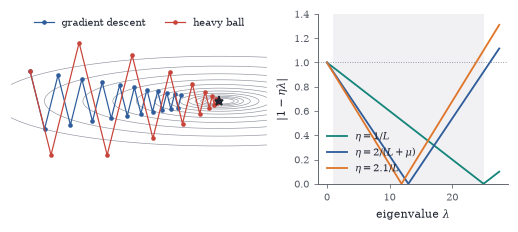

In [2]:
A2 = np.diag([1.0, 25.0]); mu, L = 1.0, 25.0; Xg, Yg = np.meshgrid(np.linspace(-11, 2.5, 300), np.linspace(-2.6, 2.6, 200)); Fg = 0.5 * (Xg**2 + 25 * Yg**2)
fig, axs = plt.subplots(1, 2, figsize=(W, 2.0), gridspec_kw=dict(width_ratios=[1.35, 1]))
axs[0].contour(Xg, Yg, Fg, levels=np.geomspace(0.3, 70, 12), colors=GRAY, linewidths=0.4)
x = np.array([-10.0, 1.6]); P = [x.copy()]; eta = 2 / (L + mu)
for _ in range(20): x = x - eta * A2 @ x; P.append(x.copy())
P = np.array(P); axs[0].plot(P[:, 0], P[:, 1], "o-", color=BLUE, ms=2, lw=0.8, label="gradient descent")
beta = ((np.sqrt(L) - 1) / (np.sqrt(L) + 1)) ** 2; etah = 4 / (np.sqrt(L) + 1) ** 2; x = np.array([-10.0, 1.6]); xp = x.copy(); Q = [x.copy()]
for _ in range(20): x, xp = x - etah * A2 @ x + beta * (x - xp), x; Q.append(x.copy())
Q = np.array(Q); axs[0].plot(Q[:, 0], Q[:, 1], "o-", color=RED, ms=2, lw=0.8, label="heavy ball"); axs[0].plot(0, 0, "*", color=INK, ms=6)
axs[0].set_aspect("equal"); axs[0].axis("off"); axs[0].legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, fontsize=6.5, frameon=False)
lam = np.linspace(0, 27.5, 400)
for et, c, lab in [(1 / L, TEAL, r"$\eta=1/L$"), (2 / (L + mu), BLUE, r"$\eta=2/(L+\mu)$"), (2.1 / L, ORANGE, r"$\eta=2.1/L$")]:
    axs[1].plot(lam, np.abs(1 - et * lam), color=c, label=lab)
axs[1].axvspan(mu, L, color=LIGHT, alpha=0.6, lw=0); axs[1].axhline(1, color=GRAY, lw=0.6, ls=":"); axs[1].set_ylim(0, 1.4); axs[1].set_xlabel(r"eigenvalue $\lambda$"); axs[1].set_ylabel(r"$|1-\eta\lambda|$"); axs[1].legend(fontsize=6.5, frameon=False, loc="lower left")

Large learning rates select flat minima. Gradient descent on $f(a,b)=\frac12(ab-1)^2$ from $(a,b)=(6,0.05)$, whose nearest minimum has sharpness $\approx36$. Left: trajectories in the $(a,b)$ plane; the minima form the hyperbola $ab=1$ (grey). With $\eta=0.01$ the iterates go straight to the sharp nearby minimum; with $\eta=0.07$ and $\eta=0.1$ (both above $2/36$) they oscillate, are thrown away, and land at flatter minima. Right: sharpness $a^2+b^2$ along each run, with the stability thresholds $2/\eta$ dashed; each run ends below its own threshold.

(3, 300)

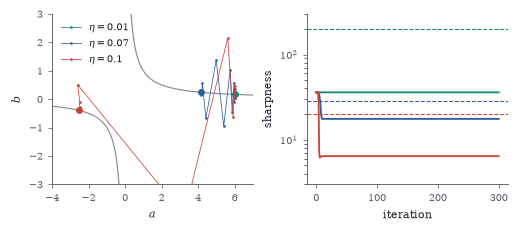

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(W, 2.0))
t = np.linspace(0.12, 7, 300); axs[0].plot(t, 1 / t, color=GRAY, lw=0.8); axs[0].plot(-t, -1 / t, color=GRAY, lw=0.8)
for eta, c in [(0.01, TEAL), (0.07, BLUE), (0.1, RED)]:
    a, b = 6.0, 0.05; P = [(a, b)]
    for _ in range(300): r = a * b - 1; a, b = a - eta * r * b, b - eta * r * a; P.append((a, b))
    P = np.array(P); axs[0].plot(P[:, 0], P[:, 1], ".-", color=c, ms=1.5, lw=0.5, label=rf"$\eta={eta}$"); axs[0].plot(*P[-1], "o", color=c, ms=3.5)
    sh = P[:, 0] ** 2 + P[:, 1] ** 2; axs[1].semilogy(sh, color=c); axs[1].axhline(2 / eta, color=c, ls="--", lw=0.7)
axs[0].set_xlim(-4, 7); axs[0].set_ylim(-3, 3); axs[0].set_xlabel("$a$"); axs[0].set_ylabel("$b$"); axs[0].legend(fontsize=6.5, frameon=False, loc="upper left")
axs[1].set_xlabel("iteration"); axs[1].set_ylabel("sharpness"); axs[1].set_ylim(3, 300)

First-order methods on a quadratic in $\R^{200}$ with eigenvalues spread over $[1,1000]$ ($\kappa=1000$). Left: relative error against iteration for gradient descent (optimal fixed step), heavy ball, Nesterov's method and conjugate gradients; the dashed lines show the rates $\frac{\kappa-1}{\kappa+1}$ and $\frac{\sqrt\kappa-1}{\sqrt\kappa+1}$. Right: the modulus of the heavy-ball iteration's eigenvalues as a function of $\lambda$; on the whole interval $[\mu,L]$ it is constant, equal to $\sqrt\beta$, while gradient descent's factor $\abs{1-\eta\lambda}$ (grey) is close to $1$ at the bottom of the spectrum.

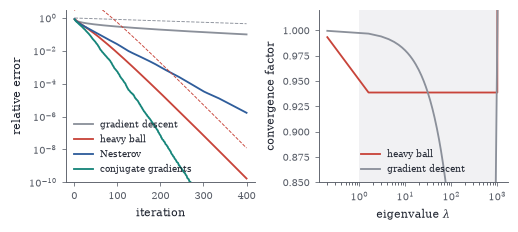

In [4]:
rng = np.random.default_rng(1); n = 200; lam = np.concatenate([[1.0, 1000.0], np.geomspace(1, 1000, n - 2)]); Qm, _ = np.linalg.qr(rng.normal(size=(n, n))); A = (Qm * lam) @ Qm.T
xs = rng.normal(size=n); b = A @ xs; mu, L = 1.0, 1000.0; kap = L / mu; K = 400; nrm = np.linalg.norm(xs)
def run(step):
    x = np.zeros(n); xp = x.copy(); out = []
    for k in range(K): x, xp = step(x, xp, k), x; out.append(np.linalg.norm(x - xs) / nrm)
    return out
gd = run(lambda x, xp, k: x - 2 / (L + mu) * (A @ x - b))
bt = ((np.sqrt(kap) - 1) / (np.sqrt(kap) + 1)) ** 2; eh = 4 / (np.sqrt(L) + np.sqrt(mu)) ** 2
hb = run(lambda x, xp, k: x - eh * (A @ x - b) + bt * (x - xp))
bn = (np.sqrt(kap) - 1) / (np.sqrt(kap) + 1)
def nest(x, xp, k): y = x + bn * (x - xp); return y - (A @ y - b) / L
ne = run(nest)
x = np.zeros(n); r = b.copy(); p = r.copy(); cg = []
for k in range(K):
    if np.linalg.norm(r) < 1e-14: cg.append(cg[-1]); continue
    Ap = A @ p; al = r @ r / (p @ Ap); x = x + al * p; rn = r - al * Ap; p = rn + (rn @ rn) / (r @ r) * p; r = rn; cg.append(np.linalg.norm(x - xs) / nrm)
fig, axs = plt.subplots(1, 2, figsize=(W, 2.0)); it = np.arange(1, K + 1)
for d, c, lab in [(gd, GRAY, "gradient descent"), (hb, RED, "heavy ball"), (ne, BLUE, "Nesterov"), (cg, TEAL, "conjugate gradients")]: axs[0].semilogy(it, d, color=c, label=lab)
axs[0].semilogy(it, ((kap - 1) / (kap + 1)) ** it, "--", color=GRAY, lw=0.6); axs[0].semilogy(it, 3 * it * np.sqrt(bt) ** it, "--", color=RED, lw=0.6)
axs[0].set_ylim(1e-10, 3); axs[0].set_xlabel("iteration"); axs[0].set_ylabel("relative error"); axs[0].legend(fontsize=6, frameon=False, loc="lower left")
ll = np.linspace(0.2, 1100, 800); rho = [np.abs(np.roots([1, -(1 + bt - eh * l), bt])).max() for l in ll]
axs[1].plot(ll, rho, color=RED, label="heavy ball"); axs[1].plot(ll, np.abs(1 - 2 / (L + mu) * ll), color=GRAY, label="gradient descent"); axs[1].axvspan(mu, L, color=LIGHT, alpha=0.6, lw=0)
axs[1].set_xscale("log"); axs[1].set_ylim(0.85, 1.02); axs[1].set_xlabel(r"eigenvalue $\lambda$"); axs[1].set_ylabel("convergence factor"); axs[1].legend(fontsize=6, frameon=False, loc="lower center")

Gradient descent (fixed step $0.0015$, close to the largest stable one near the minimum), and BFGS and Newton's method with backtracking line search, on the Rosenbrock function $f(x,y)=(1-x)^2+100(y-x^2)^2$ from $(-1.2,1)$. Left: the iterates; the minimum $(1,1)$ lies at the end of a curved, narrow valley. Gradient descent (black) drops quickly into the valley, then crawls along its floor and after 2000 steps has only reached $(0.84,0.71)$; BFGS (blue) and Newton (red) follow the valley. Right: $f(x_k)$ on a log scale; Newton's quadratic and BFGS's superlinear convergence appear as curves that bend sharply downward at the end.

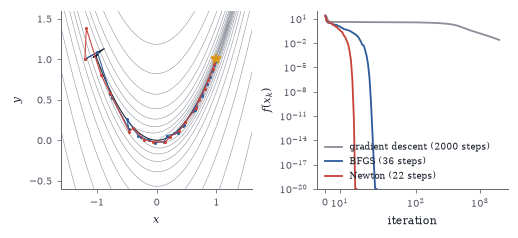

In [5]:
def fr(z): return (1 - z[0]) ** 2 + 100 * (z[1] - z[0] ** 2) ** 2
def gr(z): return np.array([-2 * (1 - z[0]) - 400 * z[0] * (z[1] - z[0] ** 2), 200 * (z[1] - z[0] ** 2)])
def hs(z): return np.array([[2 - 400 * (z[1] - 3 * z[0] ** 2), -400 * z[0]], [-400 * z[0], 200.0]])
def ls(z, d, g):
    t = 1.0
    while fr(z + t * d) > fr(z) + 1e-4 * t * g @ d and t > 1e-12: t *= 0.5
    return t
def opt(kind, iters):
    z = np.array([-1.2, 1.0]); Hi = np.eye(2); P = [z.copy()]; F = [fr(z)]
    for _ in range(iters):
        g = gr(z)
        if np.linalg.norm(g) < 1e-12: break
        if kind == "gd": d = -g
        elif kind == "newton":
            Hm = hs(z); ev = np.linalg.eigvalsh(Hm); d = -np.linalg.solve(Hm + max(0, 1e-3 - ev[0]) * np.eye(2), g)
        else: d = -Hi @ g
        t = 0.0015 if kind == "gd" else ls(z, d, g); zn = z + t * d
        if kind == "bfgs":
            s, y = zn - z, gr(zn) - g
            if y @ s > 1e-14: r = 1 / (y @ s); I2 = np.eye(2); Hi = (I2 - r * np.outer(s, y)) @ Hi @ (I2 - r * np.outer(y, s)) + r * np.outer(s, s)
        z = zn; P.append(z.copy()); F.append(fr(z))
    return np.array(P), np.array(F)
fig, axs = plt.subplots(1, 2, figsize=(W, 2.05)); xg, yg = np.meshgrid(np.linspace(-1.6, 1.6, 300), np.linspace(-0.6, 1.6, 300))
axs[0].contour(xg, yg, (1 - xg) ** 2 + 100 * (yg - xg**2) ** 2, levels=np.geomspace(0.05, 600, 14), colors=GRAY, linewidths=0.35)
for kind, it, c, lab in [("gd", 2000, GRAY, "gradient descent"), ("bfgs", 200, BLUE, "BFGS"), ("newton", 100, RED, "Newton")]:
    P, F = opt(kind, it); axs[0].plot(P[:, 0], P[:, 1], ".-" if kind != "gd" else "-", color=c if kind != "gd" else INK, ms=2, lw=0.7)
    axs[1].semilogy(np.arange(len(F)), np.maximum(F, 1e-20), color=c, label=f"{lab} ({len(F) - 1} steps)")
axs[0].plot(1, 1, "*", color=GOLD, ms=7, zorder=5); axs[0].set_xlabel("$x$"); axs[0].set_ylabel("$y$")
axs[1].set_xscale("symlog", linthresh=50); axs[1].set_ylim(1e-20, 1e2); axs[1].set_xlabel("iteration"); axs[1].set_ylabel(r"$f(x_k)$"); axs[1].legend(fontsize=5.8, frameon=False, loc="lower left")

The geometry of Lagrange and KKT conditions. Left: minimizing $f(x)=\frac12\norm{x-c}_{H}^2$ (elliptical level sets) on the line $a\T x=b$; at the solution the level set is tangent to the line and $\nabla f(x^*)$ is parallel to the normal $a$, $\nabla f(x^*)=-\lambda a$ (red arrow). Right: the same objective on the half-plane $a\T x\le b$ for two centres. When the unconstrained minimum $c_1$ is feasible, the constraint is inactive and its multiplier is zero; when $c_2$ is infeasible, the solution lies on the boundary, and $-\nabla f$ points outward along $a$, with $\nu>0$.

Text(-1.3, -1.25, 'feasible')

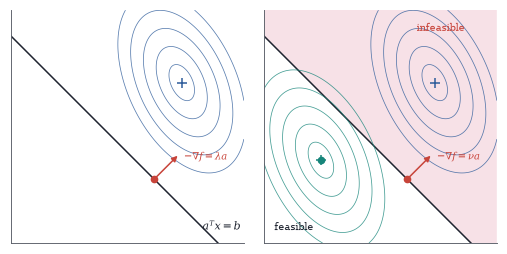

In [6]:
Hq = np.array([[2.0, 0.6], [0.6, 1.0]]); av = np.array([1.0, 1.0]); bb = 1.0
def solve_eq(c):
    K = np.block([[Hq, av[:, None]], [av[None, :], np.zeros((1, 1))]]); sol = np.linalg.solve(K, np.concatenate([Hq @ c, [bb]])); return sol[:2], sol[2]
g1 = np.linspace(-1.5, 3, 300); Xg, Yg = np.meshgrid(g1, g1); D = np.stack([Xg, Yg], -1)
fig, axs = plt.subplots(1, 2, figsize=(W, 2.2))
for ax, cs in [(axs[0], [np.array([1.8, 1.6])]), (axs[1], [np.array([-0.4, 0.1]), np.array([1.8, 1.6])])]:
    ax.fill_between(g1, bb - g1, 3.5 if ax is axs[1] else bb - g1, color=ROSE, alpha=0.25 if ax is axs[1] else 0, lw=0)
    ax.plot(g1, bb - g1, color=INK, lw=1.0)
    for c, col in zip(cs, [TEAL, BLUE] if len(cs) == 2 else [BLUE]):
        E = D - c; Fv = 0.5 * np.einsum("...i,ij,...j", E, Hq, E); ax.contour(Xg, Yg, Fv, levels=[0.05, 0.2, 0.45, 0.8, 1.25], colors=col, linewidths=0.5, alpha=0.8)
        ax.plot(*c, "+", color=col, ms=6)
        if av @ c <= bb: ax.plot(*c, "o", color=col, ms=4); continue
        xs_, lam_ = solve_eq(c); ax.plot(*xs_, "o", color=RED, ms=4); gv = Hq @ (xs_ - c); gv = gv / np.linalg.norm(gv) * 0.7
        ax.annotate("", xy=xs_ - gv, xytext=xs_, arrowprops=dict(arrowstyle="-|>", color=RED, lw=1)); ax.text(*(xs_ - gv + np.array([0.08, -0.12])), r"$-\nabla f=\lambda a$" if ax is axs[0] else r"$-\nabla f=\nu a$", fontsize=6.5, color=RED)
    ax.set_xlim(-1.5, 3); ax.set_ylim(-1.5, 3); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
axs[0].text(2.2, -1.25, r"$a^{T}x=b$", fontsize=7); axs[1].text(1.45, 2.6, "infeasible", fontsize=6.5, color=RED); axs[1].text(-1.3, -1.25, "feasible", fontsize=6.5)

The elliptope: all $3\times3$ correlation matrices $\begin{bmatrix}1&x&y\\x&1&z\\y&z&1\end{bmatrix}\ge0$, drawn in $(x,y,z)$ coordinates. The boundary is the surface $1+2xyz-x^2-y^2-z^2=0$ where the determinant vanishes. Its four vertices (red) are the rank-one matrices $vv^{T}$ with $v\in\{\pm1\}^3$, which correspond to the cuts of a triangle; the semidefinite relaxation of max-cut optimizes a linear function over this inflated tetrahedron instead of over its vertices.

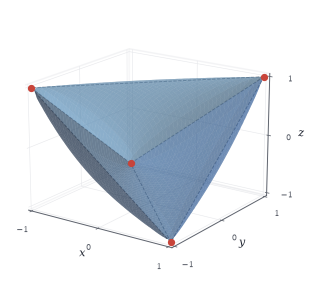

In [7]:
fig = plt.figure(figsize=(W * 0.62, W * 0.55)); ax = ax3d(fig, elev=18, azim=-55, lim=1.05)
u = np.linspace(-1, 1, 70); Xs, Ys = np.meshgrid(u, u); rt = np.sqrt(np.clip((1 - Xs**2) * (1 - Ys**2), 0, None))
for sgn, col in [(1, SKY), (-1, BLUE)]: ax.plot_surface(Xs, Ys, Xs * Ys + sgn * rt, color=col, alpha=0.45, linewidth=0, antialiased=True, shade=True)
V = np.array([[1, 1, 1], [1, -1, -1], [-1, 1, -1], [-1, -1, 1]])
for i in range(4):
    for j in range(i + 1, 4): ax.plot(*zip(V[i], V[j]), color=GRAY, lw=0.6, ls="--")
ax.scatter(V[:, 0], V[:, 1], V[:, 2], color=RED, s=14, depthshade=False); ax.set_xlabel("$x$", fontsize=7, labelpad=-8); ax.set_ylabel("$y$", fontsize=7, labelpad=-8); ax.set_zlabel("$z$", fontsize=7, labelpad=-8)
ax.set_xticks([-1, 0, 1]); ax.set_yticks([-1, 0, 1]); ax.set_zticks([-1, 0, 1])

The lasso $\min\frac12\norm{Ax-b}^2+\lambda\norm x_1$ for a random $A\in\R^{60\times150}$ and a $6$-sparse $x$ with noise. Left: objective gap of ISTA (proximal gradient) and FISTA (accelerated) against iteration; the dashed lines show the $O(1/k)$ and $O(1/k^2)$ rates, which are pessimistic once the active set settles. Right: the regularization path, each coefficient of the solution as a function of $\lambda$; large $\lambda$ gives $x=0$, and coefficients enter one by one as $\lambda$ decreases. The six true nonzero coefficients (coloured) dominate the path; the others (grey) stay near zero and are fitted noise.

Text(0, 0.5, 'coefficient')

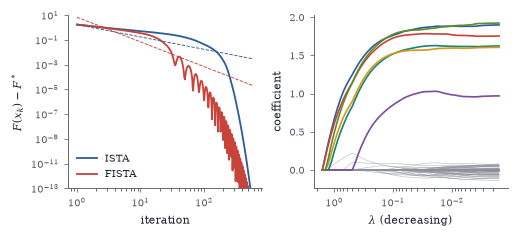

In [8]:
rng = np.random.default_rng(3); m, p = 60, 150; A = rng.normal(size=(m, p)) / np.sqrt(m); xt = np.zeros(p); sup = rng.choice(p, 6, replace=False); xt[sup] = rng.choice([-1, 1], 6) * rng.uniform(1, 2, 6)
b = A @ xt + 0.05 * rng.normal(size=m); Lc = np.linalg.norm(A, 2) ** 2
def soft(v, t): return np.sign(v) * np.maximum(np.abs(v) - t, 0)
def Fobj(x, lam): return 0.5 * np.sum((A @ x - b) ** 2) + lam * np.abs(x).sum()
def fista(lam, iters, x0=None, accel=True, rec=False):
    x = np.zeros(p) if x0 is None else x0.copy(); y = x.copy(); t = 1.0; hist = []
    for _ in range(iters):
        xn = soft(y - (A.T @ (A @ y - b)) / Lc, lam / Lc)
        if accel: tn = (1 + np.sqrt(1 + 4 * t * t)) / 2; y = xn + (t - 1) / tn * (xn - x); t = tn
        else: y = xn
        x = xn
        if rec: hist.append(Fobj(x, lam))
    return x, np.array(hist)
lam0 = 0.1; xstar, _ = fista(lam0, 20000); Fs = Fobj(xstar, lam0)
_, hi = fista(lam0, 600, accel=False, rec=True); _, hf = fista(lam0, 600, rec=True); k = np.arange(1, 601)
fig, axs = plt.subplots(1, 2, figsize=(W, 2.05))
axs[0].loglog(k, hi - Fs + 1e-16, color=BLUE, label="ISTA"); axs[0].loglog(k, hf - Fs + 1e-16, color=RED, label="FISTA")
axs[0].loglog(k, (hi[0] - Fs) / k, "--", color=BLUE, lw=0.6); axs[0].loglog(k, (hf[0] - Fs) * 4 / k**2, "--", color=RED, lw=0.6)
axs[0].set_ylim(1e-13, 10); axs[0].set_xlabel("iteration"); axs[0].set_ylabel(r"$F(x_k)-F^*$"); axs[0].legend(fontsize=6.5, frameon=False, loc="lower left")
lmax = np.abs(A.T @ b).max(); lams = np.geomspace(lmax, lmax * 1e-3, 60); path = []; x = np.zeros(p)
for lm in lams: x, _ = fista(lm, 400, x0=x); path.append(x.copy())
path = np.array(path)
for j in range(p):
    if j not in sup: axs[1].semilogx(lams, path[:, j], color=GRAY, lw=0.4, alpha=0.6)
for j, c in zip(sup, PALETTE): axs[1].semilogx(lams, path[:, j], color=c, lw=1.1)
axs[1].invert_xaxis(); axs[1].set_xlabel(r"$\lambda$ (decreasing)"); axs[1].set_ylabel("coefficient")

Stochastic gradient descent on least squares, $A\in\R^{500\times20}$, one row per step. Left: on a consistent system, SGD with the Kaczmarz step converges linearly, faster than the randomized Kaczmarz bound (dashed), which is a worst case; on an inconsistent system (noise added to $b$), the same iteration stalls at a noise floor. Right: on the inconsistent system, halving and quartering the step lowers the floor in proportion but slows the approach, and a decaying step $\eta_k\propto1/k$ keeps improving at the rate $1/k$; the curves are averages over $10$ runs.

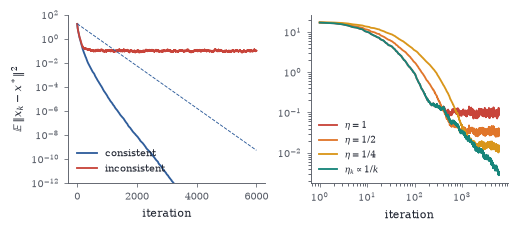

In [9]:
rng = np.random.default_rng(4); N, d = 500, 20; A = rng.normal(size=(N, d)) * np.linspace(0.3, 1.5, d); xt = rng.normal(size=d); b0 = A @ xt; bn = b0 + 0.3 * rng.normal(size=N)
xls = np.linalg.lstsq(A, bn, rcond=None)[0]; rn = (A**2).sum(1); pr = rn / rn.sum(); K = 6000
def sgd(b, xstar, step, runs=10):
    out = np.zeros(K)
    for r in range(runs):
        g = np.random.default_rng(100 + r); x = np.zeros(d); idx = g.choice(N, K, p=pr)
        for k in range(K):
            i = idx[k]; x = x + step(k) * (b[i] - A[i] @ x) / rn[i] * A[i]; out[k] += np.sum((x - xstar) ** 2) / runs
    return out
fig, axs = plt.subplots(1, 2, figsize=(W, 2.0)); it = np.arange(1, K + 1)
c1 = sgd(b0, xt, lambda k: 1.0); c2 = sgd(bn, xls, lambda k: 1.0); s = np.linalg.svd(A, compute_uv=False); rate = 1 - s[-1] ** 2 / np.sum(s**2)
axs[0].semilogy(it, c1, color=BLUE, label="consistent"); axs[0].semilogy(it, c2, color=RED, label="inconsistent"); axs[0].semilogy(it, np.sum(xt**2) * rate**it, "--", color=BLUE, lw=0.6)
axs[0].set_ylim(1e-12, 1e2); axs[0].set_xlabel("iteration"); axs[0].set_ylabel(r"$\mathbb{E}\,\|x_k-x^*\|^2$"); axs[0].legend(fontsize=6.5, frameon=False, loc="lower left")
for st, c, lab in [(lambda k: 1.0, RED, r"$\eta=1$"), (lambda k: 0.5, ORANGE, r"$\eta=1/2$"), (lambda k: 0.25, GOLD, r"$\eta=1/4$"), (lambda k: min(1.0, 400 / (k + 1)), TEAL, r"$\eta_k\propto 1/k$")]:
    axs[1].loglog(it, sgd(bn, xls, st), color=c, label=lab)
axs[1].set_xlabel("iteration"); axs[1].legend(fontsize=6, frameon=False, loc="lower left")

Adam is not rotation invariant. Quadratic $\frac12x^{T}Ax$ in $\R^{50}$ with eigenvalues from $1$ to $1000$, either diagonal (axis-aligned) or rotated by a random orthogonal matrix, from equivalent starting points. Gradient descent (step $1/L$) behaves identically in both cases. Adam (step $0.03$, linearly decayed) is dramatically faster when the curvature is axis-aligned, since its per-coordinate scaling then equalizes the curvatures, and loses its advantage when the same curvature is rotated.

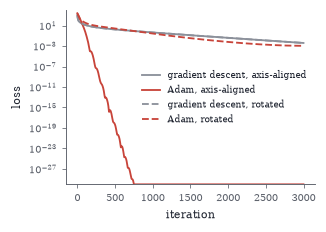

In [10]:
rng = np.random.default_rng(0); d = 50; lam = np.geomspace(1, 1000, d); Qr, _ = np.linalg.qr(rng.normal(size=(d, d))); x0 = rng.normal(size=d); T = 3000
fig, ax = plt.subplots(figsize=(W * 0.62, 2.0))
for name, A_, xi, ls_ in [("axis-aligned", np.diag(lam), x0, "-"), ("rotated", (Qr * lam) @ Qr.T, Qr @ x0, "--")]:
    x = xi.copy(); fg = []
    for t in range(T): x = x - (A_ @ x) / 1000; fg.append(0.5 * x @ A_ @ x)
    x = xi.copy(); mm = np.zeros(d); vv = np.zeros(d); fa = []
    for t in range(1, T + 1):
        g = A_ @ x; mm = 0.9 * mm + 0.1 * g; vv = 0.999 * vv + 0.001 * g * g
        x = x - 0.03 * (1 - t / (T + 1)) * (mm / (1 - 0.9**t)) / (np.sqrt(vv / (1 - 0.999**t)) + 1e-12); fa.append(0.5 * x @ A_ @ x)
    ax.semilogy(fg, color=GRAY, ls=ls_, label=f"gradient descent, {name}"); ax.semilogy(np.maximum(fa, 1e-30), color=RED, ls=ls_, label=f"Adam, {name}")
ax.set_ylim(1e-30, 1e4); ax.set_xlabel("iteration"); ax.set_ylabel("loss"); ax.legend(fontsize=6, frameon=False, loc="center right")

In [11]:
rng = np.random.default_rng(0); X = rng.normal(size=(8, 4)); Y = rng.normal(size=(8, 3)); Wm = rng.normal(size=(4, 3)); E = rng.normal(size=(4, 3)); h = 1e-6
fW = lambda Wm: 0.5 * np.sum((X @ Wm - Y) ** 2); print("least squares:", (fW(Wm + h * E) - fW(Wm - h * E)) / (2 * h), "  vs  <grad,E> =", np.sum(X.T @ (X @ Wm - Y) * E))
B = rng.normal(size=(4, 4)); S = B @ B.T + np.eye(4); Es = rng.normal(size=(4, 4)); Es = Es + Es.T; ld = lambda M: np.linalg.slogdet(M)[1]
print("log det:      ", (ld(S + h * Es) - ld(S - h * Es)) / (2 * h), "  vs  <grad,E> =", np.sum(np.linalg.inv(S) * Es))

least squares: 22.426490268401267   vs  <grad,E> = 22.426490265096202
log det:       0.6902021105759104   vs  <grad,E> = 0.6902021098925727


In [12]:
mu, L = 1.0, 100.0; lams = np.linspace(mu, L, 200)
def worst(eta, beta): return max(np.abs(np.roots([1, -(1 + beta - eta * l), beta])).max() for l in lams)
best = min(((worst(e, bt), e, bt) for e in np.linspace(0.02, 0.04, 41) for bt in np.linspace(0.6, 0.75, 31)))
print("grid optimum: rate %.4f at eta=%.4f, beta=%.4f" % best)
print("theory:       rate %.4f at eta=%.4f, beta=%.4f" % (9 / 11, 4 / (np.sqrt(L) + np.sqrt(mu)) ** 2, (9 / 11) ** 2))

grid optimum: rate 0.8185 at eta=0.0330, beta=0.6700
theory:       rate 0.8182 at eta=0.0331, beta=0.6694


In [13]:
rng = np.random.default_rng(1); X = np.c_[np.ones(200), rng.normal(size=(200, 2))]; wt = np.array([0.5, 2.0, -1.0]); y = (rng.uniform(size=200) < 1 / (1 + np.exp(-X @ wt))).astype(float)
w = np.zeros(3)
for k in range(8):
    p = 1 / (1 + np.exp(-X @ w)); D = p * (1 - p); z = X @ w - (p - y) / D
    w = np.linalg.solve(X.T @ (D[:, None] * X), X.T @ (D * z)); print(k, np.round(w, 8), " gradient norm %.1e" % np.linalg.norm(X.T @ (1 / (1 + np.exp(-X @ w)) - y)))

0 [ 0.18913394  1.06049223 -0.60145333]  gradient norm 1.4e+01
1 [ 0.28799183  1.59947537 -0.95905003]  gradient norm 3.2e+00
2 [ 0.32746101  1.80858564 -1.09930008]  gradient norm 3.0e-01
3 [ 0.33202412  1.83214597 -1.11532484]  gradient norm 3.3e-03
4 [ 0.33207579  1.83240683 -1.11550489]  gradient norm 4.0e-07
5 [ 0.3320758   1.83240686 -1.11550491]  gradient norm 1.6e-14
6 [ 0.3320758   1.83240686 -1.11550491]  gradient norm 5.2e-15
7 [ 0.3320758   1.83240686 -1.11550491]  gradient norm 8.6e-15


In [14]:
rng = np.random.default_rng(2); n = 6; B = rng.normal(size=(n, n)); A = B @ B.T + np.eye(n); b = rng.normal(size=n)
x = np.zeros(n); H = np.eye(n); g = A @ x - b; xb = []
for k in range(n):
    d = -H @ g; t = -(g @ d) / (d @ A @ d); s = t * d; x = x + s; gn = A @ x - b; yv = gn - g; r = 1 / (yv @ s)
    H = (np.eye(n) - r * np.outer(s, yv)) @ H @ (np.eye(n) - r * np.outer(yv, s)) + r * np.outer(s, s); g = gn; xb.append(x.copy())
xc = np.zeros(n); rr = b.copy(); pp = rr.copy(); xcg = []
for k in range(n):
    Ap = A @ pp; al = rr @ rr / (pp @ Ap); xc = xc + al * pp; rn = rr - al * Ap; pp = rn + rn @ rn / (rr @ rr) * pp; rr = rn; xcg.append(xc.copy())
print("final gradient norm:", np.linalg.norm(g), "  ||H - A^-1|| =", np.linalg.norm(H - np.linalg.inv(A)))
print("max difference between BFGS and CG iterates:", max(np.linalg.norm(u - v) for u, v in zip(xb, xcg)))

final gradient norm: 8.873106340315673e-16   ||H - A^-1|| = 1.86796074412458e-14
max difference between BFGS and CG iterates: 4.699019771441663e-16


In [15]:
rng = np.random.default_rng(3); m, n = 3, 7; A = rng.normal(size=(m, n)); b = rng.normal(size=m)
K = np.block([[np.eye(n), A.T], [A, np.zeros((m, m))]]); sol = np.linalg.solve(K, np.r_[np.zeros(n), b]); ev = np.linalg.eigvalsh(K)
print("matches pinv:", np.allclose(sol[:n], np.linalg.pinv(A) @ b), "   inertia (+, -, 0):", (ev > 1e-12).sum(), (ev < -1e-12).sum(), (np.abs(ev) <= 1e-12).sum())

matches pinv: True    inertia (+, -, 0): 7 3 0


In [16]:
from scipy.optimize import linprog
pr = linprog([3, 2], A_ub=-np.array([[2, 1], [1, 2]]), b_ub=-np.array([8, 6]), bounds=[(0, None)] * 2)
du = linprog(-np.array([8, 6]), A_ub=np.array([[2, 1], [1, 2]]), b_ub=[3, 2], bounds=[(0, None)] * 2)
print("primal x =", np.round(pr.x, 6), " cost", round(pr.fun, 6), "   dual y =", np.round(du.x, 6), " value", round(-du.fun, 6))

primal x = [3.333333 1.333333]  cost 12.666667    dual y = [1.333333 0.333333]  value 12.666667


Basins of attraction of Newton's method for $u^3=v$, $v^3=u$ on $[-2,2]^2$. Each starting point is coloured by the solution it converges to within 40 steps: $(0,0)$ grey, $(1,1)$ blue, $(-1,-1)$ red; white points did not converge. The boundaries cluster along the curves $uv=\pm\frac13$, where the Jacobian is singular.

Text(0, 0.5, '$v_0$')

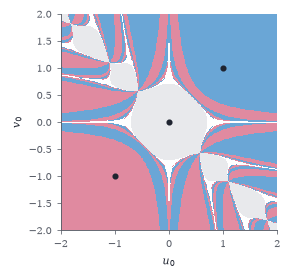

In [17]:
n = 500; g = np.linspace(-2, 2, n); U, V = np.meshgrid(g, g); u, v = U.copy(), V.copy()
for _ in range(40):
    f1, f2 = u**3 - v, v**3 - u; a, d = 3 * u**2, 3 * v**2; det = a * d - 1; det = np.where(np.abs(det) < 1e-12, 1e-12, det)
    du = -(d * f1 + f2) / det; dv = -(f1 + a * f2) / det; u, v = np.clip(u + du, -1e6, 1e6), np.clip(v + dv, -1e6, 1e6)
lab = np.full(U.shape, 3.0)
for k, (s1, s2) in enumerate([(0, 0), (1, 1), (-1, -1)]): lab[(np.abs(u - s1) < 1e-6) & (np.abs(v - s2) < 1e-6)] = k
from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(W * 0.55, W * 0.55)); ax.imshow(lab, extent=(-2, 2, -2, 2), origin="lower", cmap=ListedColormap([LIGHT, SKY, ROSE, "white"]), vmin=0, vmax=3, interpolation="nearest")
ax.plot([0, 1, -1], [0, 1, -1], "o", color=INK, ms=3); ax.set_xlabel("$u_0$"); ax.set_ylabel("$v_0$")

In [18]:
M = np.array([[1., 0, 1], [0, 4, 3], [1, 3, 0]]); print("eigenvalues of M:", np.round(np.linalg.eigvalsh(M), 4))

eigenvalues of M: [-1.8784  1.2239  5.6545]


In [19]:
from itertools import combinations
Aeq = np.array([[1., 0, 2, 1], [0, 1, 1, -1]]); beq = np.array([4., 2]); c = np.array([3., 1, 1, 1]); seen = []
for B in combinations(range(4), 2):
    Mb = Aeq[:, B]
    if abs(np.linalg.det(Mb)) < 1e-12: continue
    x = np.zeros(4); x[list(B)] = np.linalg.solve(Mb, beq)
    x = np.round(x, 12) + 0.0
    if (x >= 0).all() and not any(np.allclose(x, y) for y in seen): seen.append(x); print("corner", x, " cost", c @ x)

corner [4. 2. 0. 0.]  cost 14.0
corner [0. 0. 2. 0.]  cost 2.0
corner [0. 6. 0. 4.]  cost 10.0


In [20]:
from scipy.optimize import linprog
A = np.array([[1., 4], [3, 2]]); m, n = A.shape
res = linprog(np.r_[np.zeros(m), 1], A_ub=np.c_[A.T, -np.ones(n)], b_ub=np.zeros(n), A_eq=np.r_[np.ones(m), 0][None], b_eq=[1], bounds=[(0, None)] * m + [(None, None)])
print("X's strategy:", np.round(res.x[:m], 4), "  value:", round(res.x[m], 4))

X's strategy: [0.25 0.75]   value: 2.5


In [21]:
a, b, d = 2.0, 0.7, 1.5; De = a * d - b * b
Hs = np.array([[d * d, -2 * b * d, b * b], [-2 * b * d, 2 * (a * d + b * b), -2 * a * b], [b * b, -2 * a * b, a * a]]) / De**2
f = lambda z: -np.log(z[0] * z[2] - z[1] ** 2); z0 = np.array([a, b, d]); h = 1e-4; E = np.eye(3)
Hfd = np.array([[(f(z0 + h * E[i] + h * E[j]) - f(z0 + h * E[i] - h * E[j]) - f(z0 - h * E[i] + h * E[j]) + f(z0 - h * E[i] - h * E[j])) / (4 * h * h) for j in range(3)] for i in range(3)])
print("formula matches finite differences:", np.allclose(Hs, Hfd, atol=1e-5), "   eigenvalues:", np.round(np.linalg.eigvalsh(Hs), 4))

formula matches finite differences: True    eigenvalues: [0.2008 0.4281 1.471 ]


In [22]:
rng = np.random.default_rng(6); A = rng.normal(size=(20, 4)); xs = rng.normal(size=4); b = A @ xs
def run(B, steps=300, eta=0.05):
    g = np.random.default_rng(0); x = np.zeros(4); out = []
    for k in range(steps):
        I = g.choice(20, B, replace=False); x = x - eta * A[I].T @ (A[I] @ x - b[I]) / B; out.append(np.linalg.norm(x - xs))
    return np.array(out)
for B in (1, 2):
    r = run(B); print(f"B={B}: error after 300 steps {r[-1]:.2e}, average ratio r_k = {np.exp(np.mean(np.diff(np.log(r)))):.4f}")

B=1: error after 300 steps 1.05e-02, average ratio r_k = 0.9826
B=2: error after 300 steps 9.14e-03, average ratio r_k = 0.9821


In [23]:
rng = np.random.default_rng(8); A = rng.normal(size=(20, 10)); b = rng.normal(size=20); xls = np.linalg.lstsq(A, b, rcond=None)[0]
x = np.zeros(10); avg = np.zeros(10); cnt = 0; eta = 0.02
for k in range(20000):
    i = rng.integers(20); x = x - eta * (A[i] @ x - b[i]) * A[i]
    if k >= 5000: cnt += 1; avg += (x - avg) / cnt
print("last iterate error %.4f    averaged error %.4f" % (np.linalg.norm(x - xls), np.linalg.norm(avg - xls)))

last iterate error 0.1497    averaged error 0.0204
